In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/data.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/data.csv')

In [3]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [4]:
df.shape

(129880, 22)

In [5]:
df.isnull().sum()

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64

In [6]:
df.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,39.427957,1190.316392,2.728696,3.057599,2.756876,2.976925,3.204774,3.252633,3.441361,3.358077,3.383023,3.350878,3.632114,3.306267,3.286326,14.713713,15.091129
std,15.119360,997.452477,1.329340,1.526741,1.401740,1.278520,1.329933,1.350719,1.319289,1.334049,1.287099,1.316252,1.180025,1.266185,1.313682,38.071126,38.465650
min,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,844.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,0.000000,0.000000
75%,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,12.000000,13.000000
max,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [7]:
df.describe(include="object").T

,count,unique,top,freq
Gender,129880,2,Female,65899
Customer Type,129880,2,Loyal Customer,106100
Type of Travel,129880,2,Business travel,89693
Class,129880,3,Business,62160


In [8]:
print(df.describe(include="object").T.to_markdown())

|                |   count |   unique | top             |   freq |
|:---------------|--------:|---------:|:----------------|-------:|
| Gender         |  129880 |        2 | Female          |  65899 |
| Customer Type  |  129880 |        2 | Loyal Customer  | 106100 |
| Type of Travel |  129880 |        2 | Business travel |  89693 |
| Class          |  129880 |        3 | Business        |  62160 |


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    1298

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["satisfaction"].value_counts()

satisfaction
False    73452
True     56428
Name: count, dtype: int64

In [12]:
import matplotlib.pyplot as plt

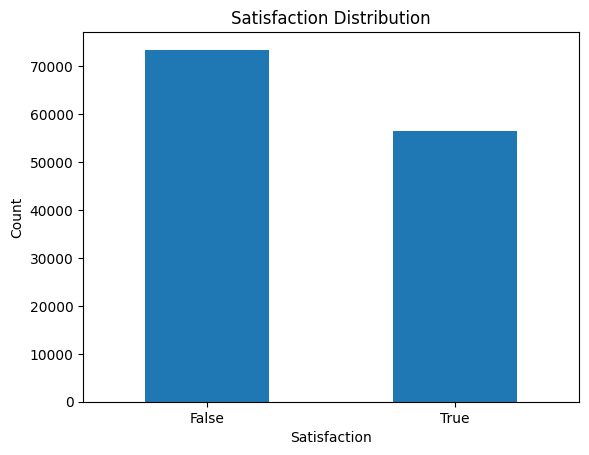

In [13]:
df["satisfaction"].value_counts().plot(kind="bar")
plt.xlabel("Satisfaction")
plt.ylabel("Count")
plt.title("Satisfaction Distribution")
plt.xticks(rotation=0)
plt.show()

In [14]:
df["Arrival Delay in Minutes"].skew()

np.float64(6.670124610533306)

In [15]:
df["Age"].skew()

np.float64(-0.003606211745335888)

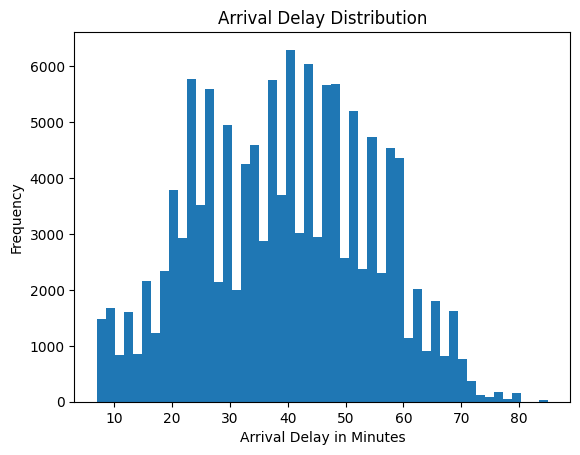

In [16]:
df["Age"].plot(kind="hist", bins=50)
plt.xlabel("Arrival Delay in Minutes")
plt.title("Arrival Delay Distribution")
plt.show()

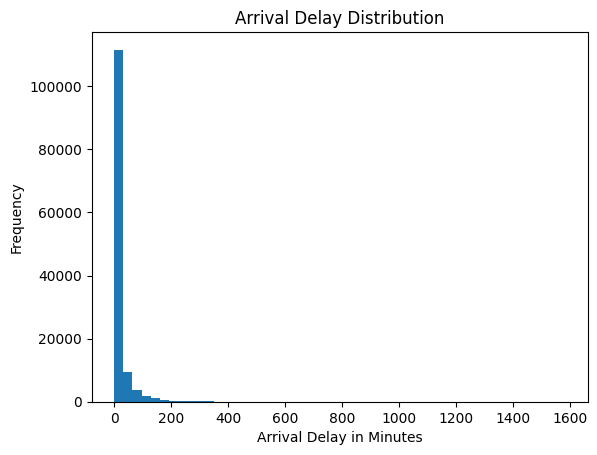

In [17]:
df["Arrival Delay in Minutes"].plot(kind="hist", bins=50)
plt.xlabel("Arrival Delay in Minutes")
plt.title("Arrival Delay Distribution")
plt.show()

In [18]:
median_delay = df["Arrival Delay in Minutes"].median()
df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(median_delay)

In [19]:
df.isnull().sum()

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

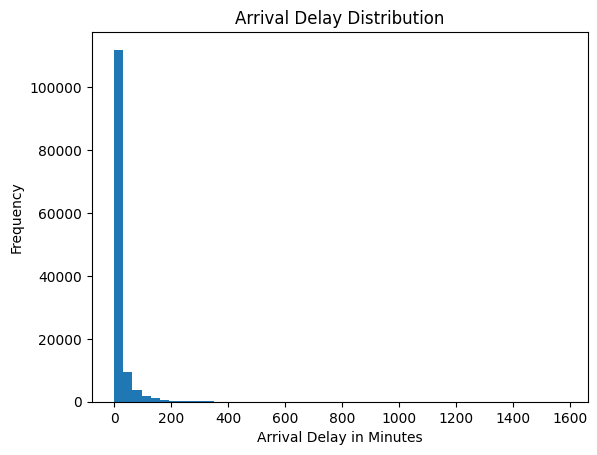

In [20]:
df["Arrival Delay in Minutes"].plot(kind="hist", bins=50)
plt.xlabel("Arrival Delay in Minutes")
plt.title("Arrival Delay Distribution")
plt.show()

In [21]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix["satisfaction"].sort_values(ascending=False)

satisfaction                         1.000000
Online boarding                      0.501749
Inflight entertainment               0.398234
Seat comfort                         0.348829
On-board service                     0.322205
Leg room service                     0.312424
Cleanliness                          0.307035
Flight Distance                      0.298085
Inflight wifi service                0.283460
Baggage handling                     0.248680
Checkin service                      0.237252
Food and drink                       0.211340
Ease of Online booking               0.168877
Age                                  0.134091
Gate location                       -0.002793
Departure Delay in Minutes          -0.050740
Departure/Arrival time convenient   -0.054270
Arrival Delay in Minutes            -0.058145
Name: satisfaction, dtype: float64

In [22]:
import seaborn as sns

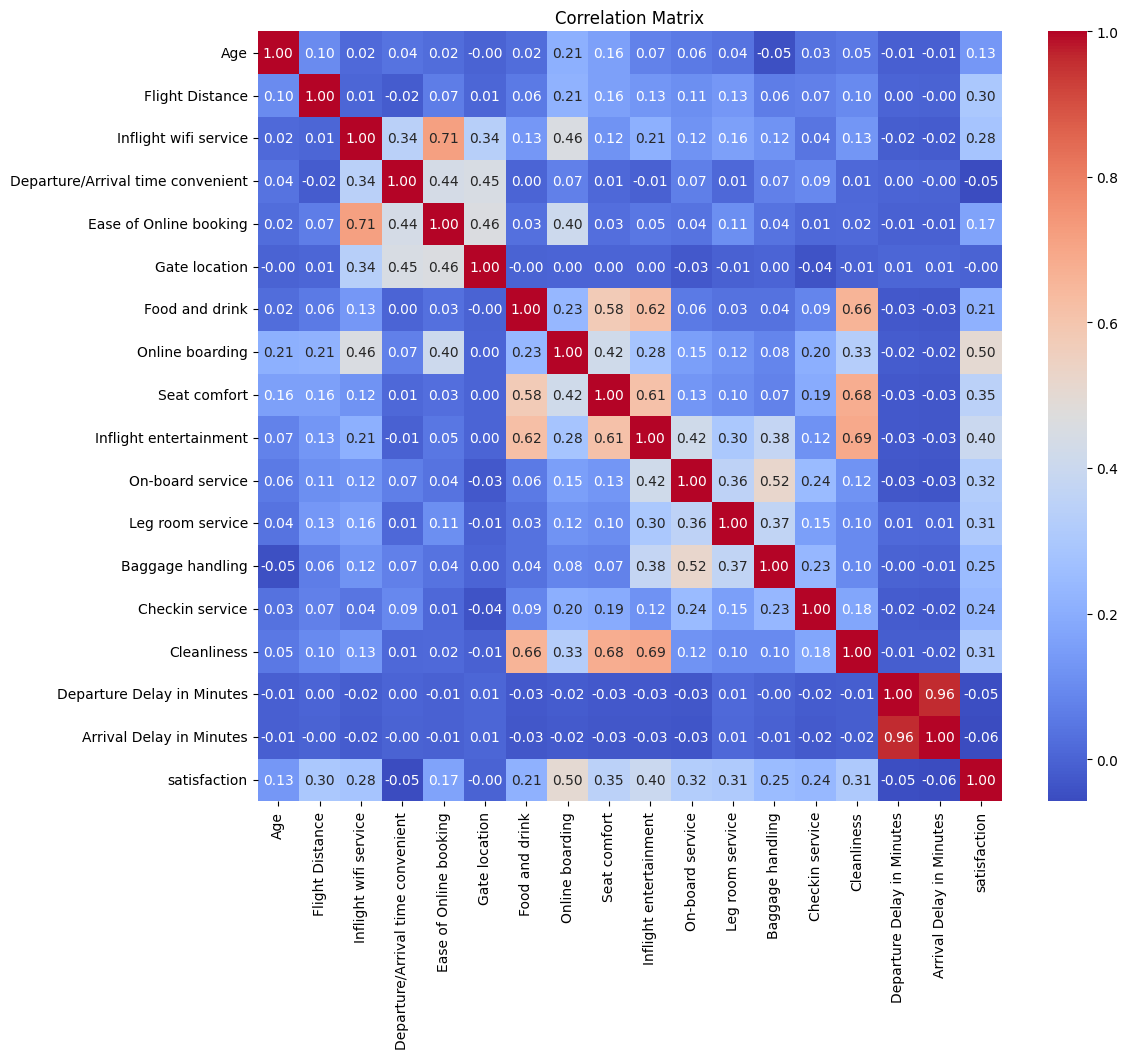

In [23]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [24]:
corr_matrix["satisfaction"].sort_values(ascending=False)

satisfaction                         1.000000
Online boarding                      0.501749
Inflight entertainment               0.398234
Seat comfort                         0.348829
On-board service                     0.322205
Leg room service                     0.312424
Cleanliness                          0.307035
Flight Distance                      0.298085
Inflight wifi service                0.283460
Baggage handling                     0.248680
Checkin service                      0.237252
Food and drink                       0.211340
Ease of Online booking               0.168877
Age                                  0.134091
Gate location                       -0.002793
Departure Delay in Minutes          -0.050740
Departure/Arrival time convenient   -0.054270
Arrival Delay in Minutes            -0.058145
Name: satisfaction, dtype: float64

In [25]:
df_corr = df.copy()

df_corr["Gender"] = df_corr["Gender"].map({"Male": 0, "Female": 1})
df_corr["Customer Type"] = df_corr["Customer Type"].map({"disloyal Customer": 0, "Loyal Customer": 1})
df_corr["Type of Travel"] = df_corr["Type of Travel"].map({"Personal Travel": 0, "Business travel": 1})
df_corr["Class"] = df_corr["Class"].map({"Eco": 0, "Eco Plus": 1, "Business": 2})

In [26]:
df_corr

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,1,13,0,1,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,0,0,25,1,2,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,1,1,26,1,2,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,1,1,25,1,2,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,0,1,61,1,2,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,0,0,34,1,2,526,3,3,3,1,...,4,4,3,2,4,4,4,0,0.0,False
129876,0,1,23,1,2,646,4,4,4,4,...,4,4,4,5,5,5,4,0,0.0,True
129877,1,1,17,0,0,828,2,5,1,5,...,2,2,4,3,4,5,2,0,0.0,False
129878,0,1,14,1,2,1127,3,3,3,3,...,4,4,3,2,5,4,4,0,0.0,True


In [27]:
corr_matrix = df_corr.corr()
corr_matrix["satisfaction"].sort_values(ascending=False)

satisfaction                         1.000000
Online boarding                      0.501749
Class                                0.492947
Type of Travel                       0.449861
Inflight entertainment               0.398234
Seat comfort                         0.348829
On-board service                     0.322205
Leg room service                     0.312424
Cleanliness                          0.307035
Flight Distance                      0.298085
Inflight wifi service                0.283460
Baggage handling                     0.248680
Checkin service                      0.237252
Food and drink                       0.211340
Customer Type                        0.186017
Ease of Online booking               0.168877
Age                                  0.134091
Gate location                       -0.002793
Gender                              -0.011236
Departure Delay in Minutes          -0.050740
Departure/Arrival time convenient   -0.054270
Arrival Delay in Minutes          

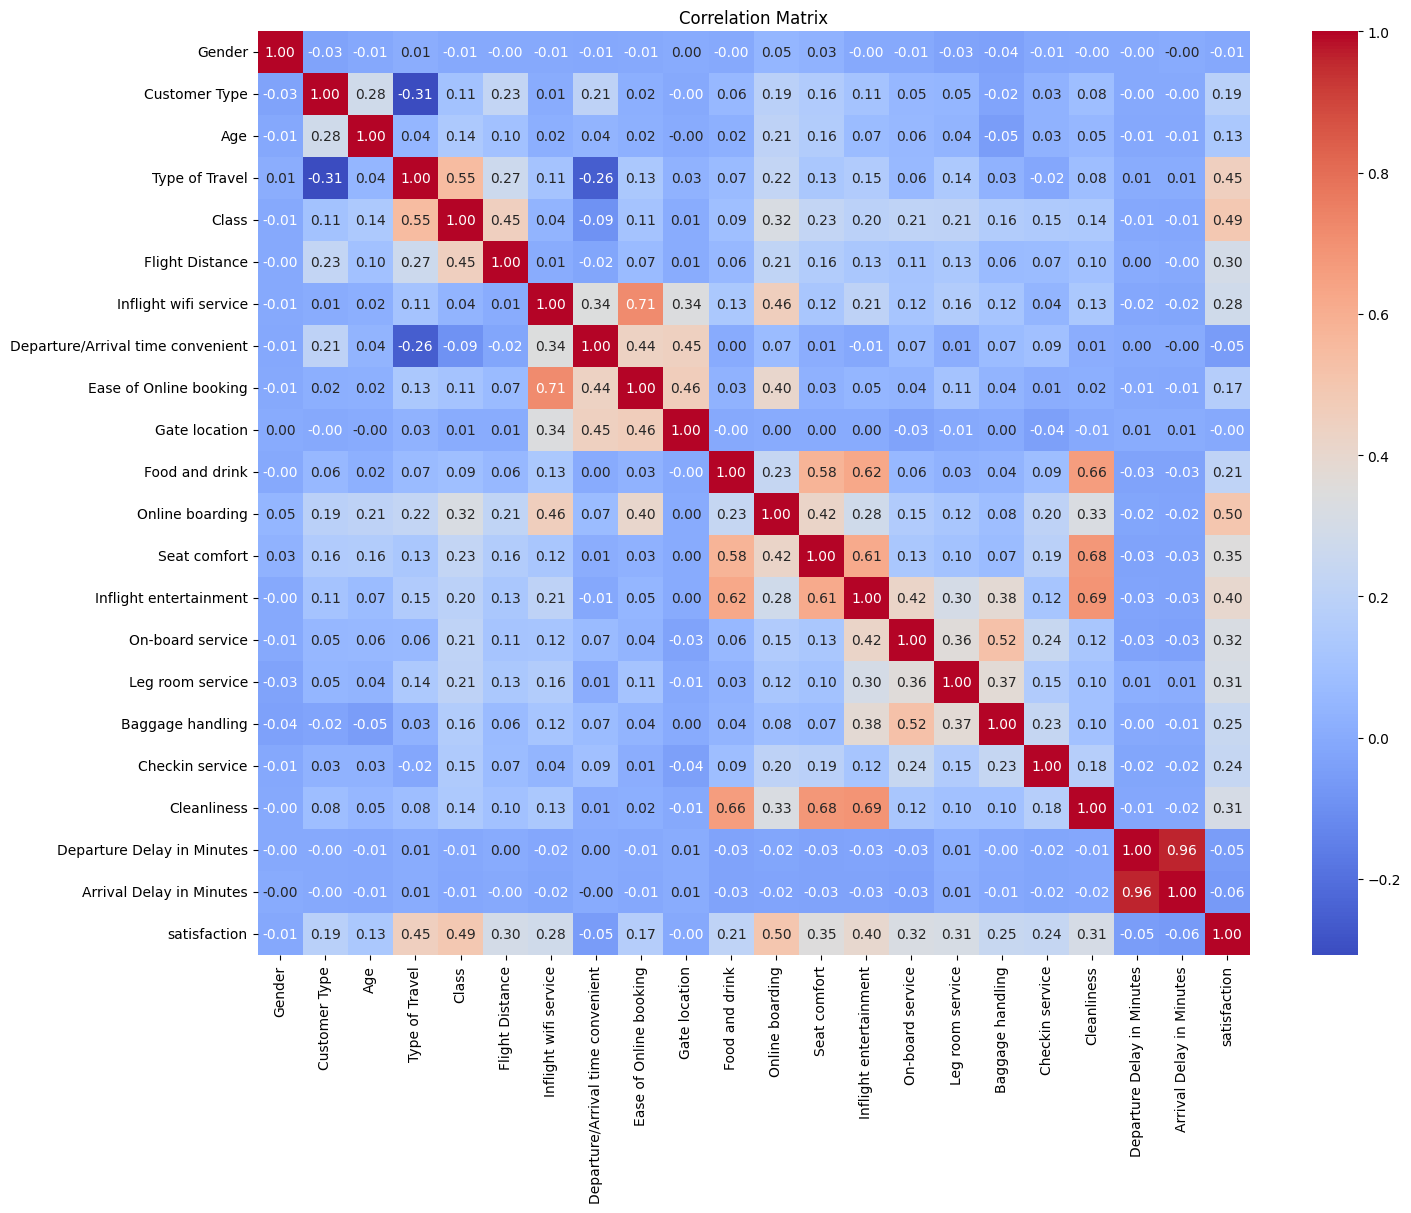

In [28]:
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [29]:
pd.crosstab(df["Class"], df["satisfaction"], normalize="index")

satisfaction,False,True
Class,,
Business,0.305566,0.694434
Eco,0.812327,0.187673
Eco Plus,0.753586,0.246414


In [30]:
pd.crosstab(df["Customer Type"], df["satisfaction"], normalize="index")

satisfaction,False,True
Customer Type,,
Loyal Customer,0.521885,0.478115
disloyal Customer,0.760303,0.239697


In [31]:
pd.crosstab(df["Type of Travel"], df["satisfaction"], normalize="index")

satisfaction,False,True
Type of Travel,,
Business travel,0.416276,0.583724
Personal Travel,0.898674,0.101326


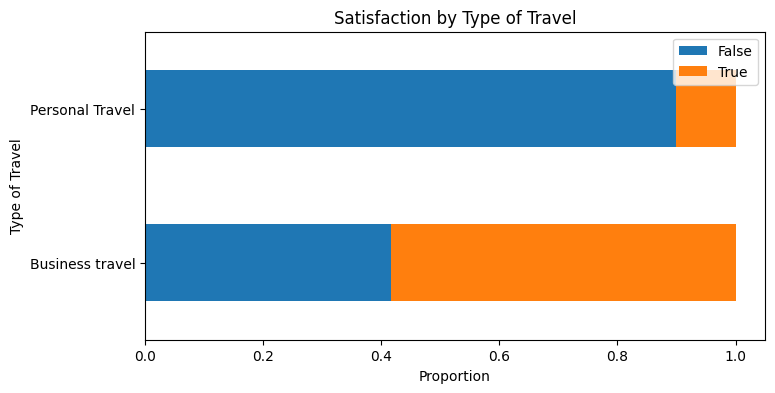

In [32]:
class_sat = pd.crosstab(df["Type of Travel"], df["satisfaction"], normalize="index")

class_sat.plot(kind="barh", stacked=True, figsize=(8, 4))
plt.xlabel("Proportion")
plt.title("Satisfaction by Type of Travel")
plt.legend(loc="upper right")
plt.show()

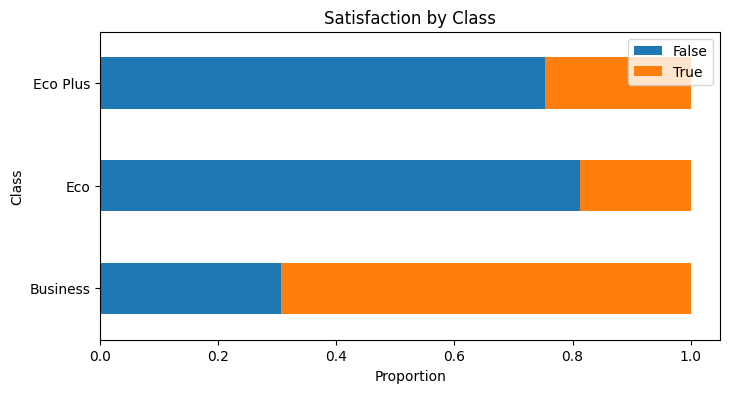

In [33]:
class_sat = pd.crosstab(df["Class"], df["satisfaction"], normalize="index")

class_sat.plot(kind="barh", stacked=True, figsize=(8, 4))
plt.xlabel("Proportion")
plt.title("Satisfaction by Class")
plt.legend(loc="upper right")
plt.show()

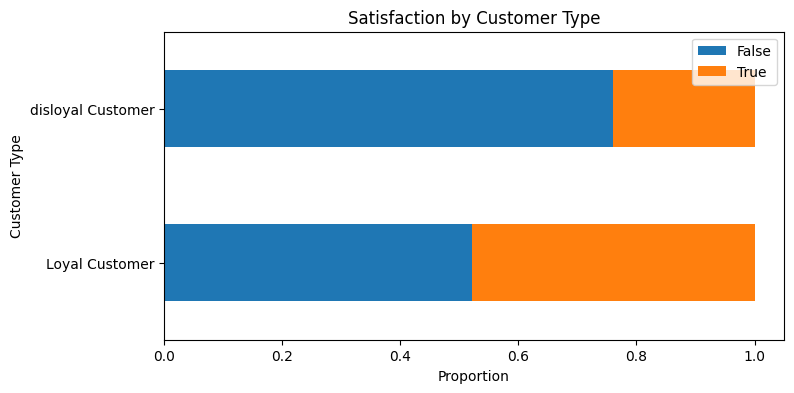

In [34]:
customer_sat = pd.crosstab(df["Customer Type"], df["satisfaction"], normalize="index")

customer_sat.plot(kind="barh", stacked=True, figsize=(8, 4))
plt.xlabel("Proportion")
plt.title("Satisfaction by Customer Type")
plt.legend(loc="upper right")
plt.show()

In [35]:
age_group = pd.cut(df["Age"], bins=[0, 18, 30, 45, 60, 100],
                   labels=["0-18", "19-30", "31-45", "46-60", "60+"])

pd.crosstab(age_group, df["satisfaction"], normalize="index")

satisfaction,False,True
Age,,
0-18,0.823848,0.176152
19-30,0.643610,0.356390
31-45,0.511933,0.488067
46-60,0.425715,0.574285
60+,0.791824,0.208176


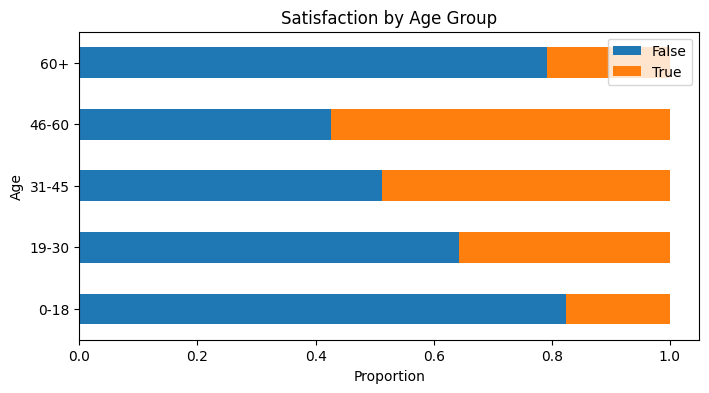

In [36]:
age_group = pd.cut(df["Age"], bins=[0, 18, 30, 45, 60, 100],
                   labels=["0-18", "19-30", "31-45", "46-60", "60+"])

age_sat = pd.crosstab(age_group, df["satisfaction"], normalize="index")

age_sat.plot(kind="barh", stacked=True, figsize=(8, 4))
plt.xlabel("Proportion")
plt.title("Satisfaction by Age Group")
plt.legend(loc="upper right")
plt.show()

In [37]:
pd.crosstab([df["Class"], df["Type of Travel"]], df["satisfaction"], normalize="index")

satisfaction                 False     True 
Class    Type of Travel                     
Business Business travel  0.279624  0.720376
         Personal Travel  0.882903  0.117097
Eco      Business travel  0.700522  0.299478
         Personal Travel  0.898046  0.101954
Eco Plus Business travel  0.607303  0.392697
         Personal Travel  0.912619  0.087381

In [38]:
pd.crosstab([df["Class"], df["Type of Travel"]], df["satisfaction"])

satisfaction              False  True 
Class    Type of Travel               
Business Business travel  16634  42853
         Personal Travel   2360    313
Eco      Business travel  17726   7578
         Personal Travel  29640   3365
Eco Plus Business travel   2977   1925
         Personal Travel   4115    394

In [39]:
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})
df["Customer Type"] = df["Customer Type"].map({"disloyal Customer": 0, "Loyal Customer": 1})
df["Type of Travel"] = df["Type of Travel"].map({"Personal Travel": 0, "Business travel": 1})

In [40]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,1,13,0,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,0,0,25,1,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,1,1,26,1,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,1,1,25,1,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,0,1,61,1,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [41]:
df = pd.get_dummies(df, columns=["Class"])

In [42]:
df.dtypes

Gender                                 int64
Customer Type                          int64
Age                                    int64
Type of Travel                         int64
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Cleanliness                            int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes             float64
satisfaction                            bool
Class_Business                          bool
Class_Eco 

In [43]:
class_cols = ["Class_Business", "Class_Eco", "Class_Eco Plus"]
df[class_cols] = df[class_cols].astype(int)
df.dtypes

Gender                                 int64
Customer Type                          int64
Age                                    int64
Type of Travel                         int64
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Cleanliness                            int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes             float64
satisfaction                            bool
Class_Business                         int64
Class_Eco 

In [44]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Class_Business,Class_Eco,Class_Eco Plus
0,0,1,13,0,460,3,4,3,1,5,...,3,4,4,5,25,18.0,False,0,0,1
1,0,0,25,1,235,3,2,3,3,1,...,5,3,1,1,1,6.0,False,1,0,0
2,1,1,26,1,1142,2,2,2,2,5,...,3,4,4,5,0,0.0,True,1,0,0
3,1,1,25,1,562,2,5,5,5,2,...,5,3,1,2,11,9.0,False,1,0,0
4,0,1,61,1,214,3,3,3,3,4,...,4,4,3,3,0,0.0,True,1,0,0


In [45]:
X = df.drop(columns=["satisfaction"])
y = df["satisfaction"]

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [47]:
X_train.shape, X_test.shape

((103904, 23), (25976, 23))

In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [49]:
X_train_scaled[:5]

array([[-1.01532374,  0.47331516, -0.55588889,  0.66807572, -0.74445713,
         1.70829964,  1.27186294,  1.60113739,  1.58079347, -0.90475974,
        -0.18545704, -1.09175691, -1.01723482,  0.47952429, -1.02835904,
         1.15880708, -0.24233373, -0.98009233, -0.38696445, -0.31435773,
         1.04350396, -0.90209561, -0.27982305],
       [-1.01532374,  0.47331516,  0.5015158 , -1.49683632, -1.00402545,
         0.20419689,  0.6164821 ,  0.17398502,  0.0152928 , -1.65624184,
        -0.18545704,  0.42395175, -1.76655081,  1.25601795,  0.49161845,
         1.15880708,  1.33710697, -1.74124603, -0.07334731, -0.21067019,
        -0.95830974,  1.10852995, -0.27982305],
       [ 0.98490753,  0.47331516,  1.09630594,  0.66807572, -0.75648347,
         1.70829964, -0.03889873,  0.17398502,  0.0152928 ,  1.34968656,
         0.55534444, -0.33390258,  0.48139716,  0.47952429,  1.25160719,
         0.31171592, -0.24233373, -1.74124603, -0.38696445, -0.39212338,
        -0.95830974,  1.1085

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [51]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [52]:
y_pred = log_model.predict(X_test_scaled)

In [53]:
knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [54]:
svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)

SVC()

In [55]:
from sklearn.metrics import accuracy_score, classification_report

In [56]:
log_pred = log_model.predict(X_test_scaled)
print(accuracy_score(y_test, log_pred))
print(classification_report(y_test, log_pred))

0.8738065906991068
              precision    recall  f1-score   support

       False       0.88      0.90      0.89     14690
        True       0.87      0.84      0.85     11286

    accuracy                           0.87     25976
   macro avg       0.87      0.87      0.87     25976
weighted avg       0.87      0.87      0.87     25976



In [57]:
knn_pred = knn_model.predict(X_test_scaled)
print(accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred))

0.9250076994148445
              precision    recall  f1-score   support

       False       0.92      0.96      0.94     14690
        True       0.94      0.89      0.91     11286

    accuracy                           0.93     25976
   macro avg       0.93      0.92      0.92     25976
weighted avg       0.93      0.93      0.92     25976



In [58]:
svm_pred = svm_model.predict(X_test_scaled)
print(accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))

0.9499153064367108
              precision    recall  f1-score   support

       False       0.95      0.96      0.96     14690
        True       0.95      0.93      0.94     11286

    accuracy                           0.95     25976
   macro avg       0.95      0.95      0.95     25976
weighted avg       0.95      0.95      0.95     25976



In [59]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [60]:
scores = cross_val_score(pipe, X, y, cv=5, scoring="accuracy")

scores

array([0.8724207 , 0.87419156, 0.87349861, 0.87850323, 0.87064983])

In [61]:
scores.mean(), scores.std()

(np.float64(0.8738527871881736), np.float64(0.0026144473889478854))

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1))
])

In [63]:
rf_pipe.fit(X_train, y_train)

Pipeline(steps=[('model', RandomForestClassifier(n_jobs=-1, random_state=42))])

In [64]:
rf_pred = rf_pipe.predict(X_test)

In [65]:
accuracy_score(y_test, rf_pred)

0.95903911302741

In [66]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

       False       0.95      0.98      0.96     14690
        True       0.97      0.94      0.95     11286

    accuracy                           0.96     25976
   macro avg       0.96      0.96      0.96     25976
weighted avg       0.96      0.96      0.96     25976



In [67]:
import joblib

joblib.dump(rf_pipe, "rf_model.pkl")

['rf_model.pkl']

In [68]:
loaded_model = joblib.load("rf_model.pkl")
loaded_model.predict(X_test[:3])

array([False, False,  True])

In [69]:
import os
os.listdir("/kaggle/working")

['.virtual_documents', 'rf_model.pkl']

In [70]:
os.path.getsize("rf_model.pkl") / 1e6   # size in MB

94.540354